# A lifetime view: TPP-1/A timing + GP-3/C physiology

We want to describe **when clinical events happen, which type occurs, and how physiology varies between irregular measurements**. We choose **TPP-1/A's mark-conditioned waiting-time flows + GP-3/C's continuous physiology and additive residual**. One causal Transformer supplies both branches. The visit branch now consumes dynamic clinical records, extending standalone TPP-A's fixed baseline and IAT-only history.

TPP-B/C already generate future feature snapshots, but those snapshots do not define a physiological function between visits. Here GP-C takes that responsibility. We do not also score the same measured values with a TPP snapshot density.

| Model | Event timing and marks | How changing patient information enters | Physiology between measurements | Measured-value distribution / fitting |
|---|---|---|---|---|
| TPP-A / 1 | Mark probabilities + mark-dependent IAT flow; censoring | Fixed baseline + previous IATs | Not modelled | Exact marked-event NLL |
| TPP-B / 2 | Same marked timing construction | Dynamic covariates + full feature-flow latents + causal history | Next-snapshot density only | Exact event + feature-snapshot NLL |
| TPP-C / 3 | Same marked timing construction | Dynamic covariates + shared feature latents; private latents retained for feature density | Next-snapshot density only | Exact event + feature-snapshot NLL |
| GP-A / 1 | Not modelled; measurement times supplied | Fixed causal prefix; later measurements condition the GP | Joint multi-output GP at arbitrary ages | Gaussian noise; exact conditional marginal NLL |
| GP-B / 2 | Not modelled; measurement times supplied | Same fixed-prefix convention | Joint GP in transformed coordinates | Invertible value warp; exact change-of-variables marginal NLL |
| GP-C / 3 | Not modelled; measurement times supplied | Same fixed-prefix convention | Joint latent physiological GP \(f\) | \(y=f+\epsilon\), flexible flow residual; variational ELBO |
| **Lifetime model** | **TPP-A-style marked flows with dynamic shared history** | **Shared Transformer, visit-origin updates; fixed GP prefix** | **GP-C latent physiology and measured-value predictions** | **Joint visit log-likelihood + physiology ELBO** |

The first three models describe events; the next three describe values at supplied times. The lifetime model combines those targets. Their raw losses therefore cannot be ranked in one table. Compare visit NLLs only on identical windows, event marks and time units; compare physiological predictive NLLs on identical held-out measurements and clinical units. A negative ELBO is not an exact marginal NLL.

## From available records to one shared state

Let \(s\) be the baseline vector, \(t_0\) the conditioning-prefix boundary and \(C\) the administrative censoring time. A token records a visit, measured value or covariate update, including its elapsed time, type and missingness; age supplies its positional code. At a completed visit origin \(t_n\), the Transformer summarises only records available up to that origin:

\[
H_n=E_\psi(\mathcal R_{\le t_n}),\qquad c_n=[s,H_n],\qquad
H_0=E_\psi(\mathcal R_{\le t_0}).
\]

The **same encoder weights** receive gradients from visits and physiology. \(H_0\) remains fixed when defining the GP prior and residual context; subsequent measurements update the GP posterior. The visit context refreshes after each visit. A covariate or measurement recorded between visits is consumed at the next visit origin, so the current interval retains a fixed waiting-time law. Immediate within-interval risk changes would require a different integrated-intensity likelihood.

## Mark first, then a mark-dependent waiting time

The event head converts \(c_n\) into three mark probabilities and timing-flow parameters:

\[
\pi_{nk}=\operatorname{softmax}_k(g_\theta(c_n)),\qquad
v_0=\log(\tau/365.2425).
\]

Two monotone sinh–arcsinh layers map each mark's positive waiting time, measured in days, to a standard normal coordinate. Each layer has shift \(a\), positive scale \(b\), skew \(\gamma\) and positive tail parameter \(\delta\), all output by the conditioning network:

\[
v_{\ell+1}=\sinh\!\left[\delta_{\ell k}
\left(\operatorname{asinh}\!\frac{v_\ell-a_{\ell k}}{b_{\ell k}}+\gamma_{\ell k}\right)\right],
\qquad z=F_{\tau,k}(\tau;c_n).
\]

Change of variables supplies the mark-conditioned density, including the log-time Jacobian. Multiplying by the mark probability gives the joint next-event law:

\[
f_k(\tau\mid c_n)=\phi(z)\left|\frac{\partial F_{\tau,k}}{\partial\tau}\right|,
\qquad p(\tau,m=k\mid c_n)=\pi_{nk}f_k(\tau\mid c_n).
\]

Here \(\phi\) is the standard normal density. Timing and type are coupled through the different \(f_k\). When the next mark is unknown, we sum over types to obtain waiting-time survival and conditional marked intensity:

\[
S_n(u)=\sum_k\pi_{nk}S_k(u\mid c_n),\qquad
\lambda_k(t_n+u\mid\mathcal H)=\frac{\pi_{nk}f_k(u\mid c_n)}{S_n(u)},
\qquad \lambda=\sum_k\lambda_k.
\]

We must account for the last event-free interval, rather than inventing an event at censoring. With \(\tau_n=t_n-t_{n-1}\), the visit log-likelihood is

\[
\ell_{\rm visits}=\sum_{n=1}^{N}
\left[\log\pi_{n-1,m_n}+\log f_{m_n}(\tau_n\mid c_{n-1})\right]
+\log S_N(C-t_N).
\]

The first target is the delay from the prefix boundary \(t_0\), rather than an unknown complete IAT from before entry. For zero subsequent visits, the survival term begins at \(t_0\).

## A continuous physiological function plus a flexible residual

For feature \(d\) and age \(t\), the GP conditioning vector contains baseline, fixed prefix state, absolute-age positional encoding and learned feature-identity embedding. A small neural map produces the kernel representation:

\[
\xi_{td}=[\operatorname{Emb}(s),H_0,\mathrm{PE}(t),\operatorname{Emb}(d)],\qquad
r_{td}=\phi_\theta(\xi_{td}),\qquad
f\sim\operatorname{GP}(m_\theta,k_\theta\mid s,H_0).
\]

Unlike the normal density \(\phi\) above, \(\phi_\theta\) here denotes a neural feature map. A feature Gram matrix plus a temporal kernel with cross-feature covariance defines the jointly consistent function prior:

\[
k((t,d),(t',d'))=
\frac{r_{td}^{\mathsf T}r_{t'd'}}{R}
+A\exp\!\left[-\frac{((t-t')/100)^2}{2\ell^2}\right](BB^{\mathsf T})_{dd'},
\qquad R=6.
\]

The actual implementation works in training-standardised physiological units. A monotone residual flow maps \(\epsilon\) to a standard normal base; generating a residual uses its inverse:

\[
\widetilde y_{jd}=\frac{y_{jd}-\mu_d^{\rm train}}{\sigma_d^{\rm train}}
=f_d(t_j)+\epsilon_{jd},\qquad
z_{jd}=F_\eta(\epsilon_{jd};\xi_{t_jd})\sim\mathcal N(0,1).
\]

The residual includes measurement error and unexplained variation; the model does not identify these separately. Conditional on the latent function and fixed query context, residual draws are independent. The measured-value density includes both the residual-flow Jacobian and conversion back to clinical units:

\[
p(y_{jd}\mid f_d(t_j),\xi_{t_jd})=
\frac{\phi(F_\eta(\widetilde y_{jd}-f_d(t_j);\xi_{t_jd}))}
{\sigma_d^{\rm train}}
\left|\partial_\epsilon F_\eta(\epsilon;\xi_{t_jd})\right|.
\]

## The complete implemented joint model

Measurement times are **conditioned upon**, rather than generated by a measurement point process. Let \(Y\) contain recorded, nonmissing values after \(t_0\), and \(V\) the marked visits after that boundary. Given the prefix, the joint latent/data density combines the GP prior, each visit density, censoring survival and each measurement density exactly once:

\[
p(f,V,Y\mid\mathcal R_{\le t_0},s,\text{measurement times})=
p_{\rm GP}(f\mid s,H_0)
\prod_{n=1}^{N}\pi_{n-1,m_n}f_{m_n}(\tau_n\mid c_{n-1})
\;S_N(C-t_N)
\prod_{(j,d)\in\mathcal M}p(y_{jd}\mid f_d(t_j),\xi_{t_jd}).
\]

The event factors depend on causal summaries of **recorded** physiology, not directly on unknown \(f\). Consequently they can remain outside latent-function integration. GP-C approximates that integration using nine whitened inducing variables \(v\), a diagonal variational distribution \(q(v)\), and a separate recognition Transformer over the conditioning measurements. Training maximises

\[
\mathcal L=\ell_{\rm visits}
+\mathbb E_{q(f)}\left[\sum_{(j,d)\in\mathcal M}
\log p(y_{jd}\mid f_d(t_j),\xi_{t_jd})\right]
-\operatorname{KL}\!\left(q(v)\Vert\mathcal N(0,I)\right).
\]

We fit shared cohort parameters on **all eligible training patients**, select the checkpoint on separate validation patients, and visualise a test patient. Fast mode uses the 100/20/10 toy split for five epochs; patients without enough measurement panels are reported and excluded.

## Read the lifetime horizon correctly

Physiology overview plots span **age 0–100**. The visit plots zoom to the observation window plus ten years on either side. Before entry they remain blank: no patient records or past forecasts are invented. Within the observed window, physiology is a **retrospective fitted distribution** using the available measurements, not a prospective evaluation. The conditioning prefix is shown; event fitting starts at its boundary. After censoring we forecast from the records known at \(C\). This is an extrapolation beyond the training observation window; age 100 is a display horizon, not a predicted death age.

If the last visit was at \(t_N\), we already know no visit occurred during \(a=C-t_N\). For a future delay \(u\), survival conditioning gives the next-event density and survival:

\[
p(U=u,m=k\mid\mathcal H_C)=
\frac{\pi_{Nk}f_k(a+u\mid c_N)}{S_N(a)},\qquad
P(U>u\mid\mathcal H_C)=\frac{S_N(a+u)}{S_N(a)}.
\]

Post-censor curves describe the **next visit**, not a simulation of every future visit. Observed event curves reset at actual visit origins; at \(C\), the displayed remaining-wait survival starts at one. It is survival without a next visit, not survival from death. Physiological curves and densities describe \(y=f+\epsilon\), with continuous, jointly sampled latent \(f\) trajectories between measurements. Predicting future categorical covariate schedules or a full birth-to-death process would require additional models.

**Clinical input encoding used throughout these models.** Categories use small learned embeddings: sex, employment, record kind and event type use two coordinates; marital status and history-variable identity use three, while GP query-output identity uses two. Missing/unseen categories are explicit. A category that does not apply to a token uses a zero padding embedding. Adapter indicators are decoded to IDs before neural computation. Physiological values remain training-standardised, with explicit missingness and known-value flags. With small vocabularies, embeddings provide a compact representation; a one-hot vector followed by a linear projection already learns category vectors, so this change does not automatically improve predictions.

Age supplies a **learned continuous absolute-age encoding**, rather than a raw content feature or a sinusoidal code. A small two-layer network maps age in years into the model's hidden dimension:

\[
\mathrm{PE}_\omega(a)=W_2\tanh\!\left(W_1\frac{a}{100}+b_1\right)+b_2.
\]

History tokens add this encoding after their learned content projection. TPP-A reconstructs record ages from entry age and accumulated IATs; dynamic TPPs and GP histories use recorded ages. Equal-age records share an encoding, while the causal attention mask still prevents attending to later records. Each conditioning network replaces age scalars with learned age encodings and categorical indicators with embeddings. All encoding parameters are trained with the model. Duration/IAT inputs retain their log scaling.

The GP still uses actual age differences as its continuous covariance coordinate; output IDs select the covariance matrix. Its neural mean, feature maps and flows receive learned age and output embeddings. This removes imposed periodicity, but does not guarantee reliable extrapolation or a biologically correct ageing trajectory.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from IPython.display import display, Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/"pyproject.toml").exists())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from lifetime_clinical.tutorials.experiments import load_toy
from lifetime_clinical.models.lifetime import LifetimeModel, prepare_lifetime_data
from lifetime_clinical.data.longitudinal import split_forecast_block
from lifetime_clinical.data.preprocessing import VARIABLES
from lifetime_clinical.data.synthetic import EVENT_TYPES, YEAR_DAYS
from lifetime_clinical.visualization.gp import plot_additive_contributions
FAST_MODE=True
EPOCHS=5 if FAST_MODE else 10
DEVICE="cuda" if torch.cuda.is_available() else "cpu"
DATA_DIR=ROOT/"data"/("toy" if FAST_MODE else "synthetic")
if DEVICE=="cpu": torch.set_num_threads(1)
plt.rcParams.update({"figure.dpi":140,"axes.spines.top":False,"axes.spines.right":False})
dataset,splits,pre=load_toy(DATA_DIR)
patients=prepare_lifetime_data(dataset,pre,splits,history_fraction=.25)
print("Dataset:",DATA_DIR.name,"Device:",DEVICE,"Epochs:",EPOCHS)
print("Eligible patients:",{k:len(v) for k,v in patients.items()})
print("Training targets:",sum(len(p.times) for p in patients['train']),"visits;",
      sum(len(p.block.y) for p in patients['train']),"measurements")

Dataset: toy Device: cpu Epochs: 5
Eligible patients: {'train': 95, 'validation': 19, 'test': 10}
Training targets: 1307 visits; 2664 measurements


### Fit the combined objective

We now fit both branches together. Each patient's objective adds its marked-visit NLL, including right censoring, to its GP-C negative ELBO. These components score different targets, so their relative magnitudes are not a ranking of the two branches. The shared parameters receive gradients from both. Validation selects the best checkpoint; all requested epochs are still completed.

In [2]:
reference=patients["train"][0]
lifetime=LifetimeModel(len(reference.block.static),reference.tokens.shape[1],hidden_dim=12,seed=42)
history=lifetime.fit(patients["train"],patients["validation"],epochs=EPOCHS,device=DEVICE)
artifact_dir=ROOT/"artifacts"/"lifetime_model"
artifact_dir.mkdir(parents=True,exist_ok=True)
torch.save({"state_dict":{k:v.detach().cpu() for k,v in lifetime.state_dict().items()},
            "static_dim":len(reference.block.static),"token_dim":reference.tokens.shape[1],
            "hidden_dim":12,"seed":42,"epochs":EPOCHS,"dataset":DATA_DIR.name,
            "measurement_scales":pre.measurement_scales,"token_feature_names":pre.token_feature_names,
            "static_feature_names":pre.static_feature_names,"splits":splits,
            "fit_history":history},artifact_dir/"checkpoint.pt")
print("Saved fitted checkpoint:",artifact_dir/"checkpoint.pt")

Epoch 0/5: train negative ELBO 199.608; validation 174.577


Epoch 1/5: train negative ELBO 169.272; validation 151.490


Epoch 2/5: train negative ELBO 165.536; validation 148.497


Epoch 3/5: train negative ELBO 164.995; validation 147.540


Epoch 4/5: train negative ELBO 162.566; validation 147.840


Epoch 5/5: train negative ELBO 161.222; validation 146.707


Saved fitted checkpoint: C:\Users\dario\Desktop\Doctorado\lifetime_clinical_tutorial\artifacts\lifetime_model\checkpoint.pt


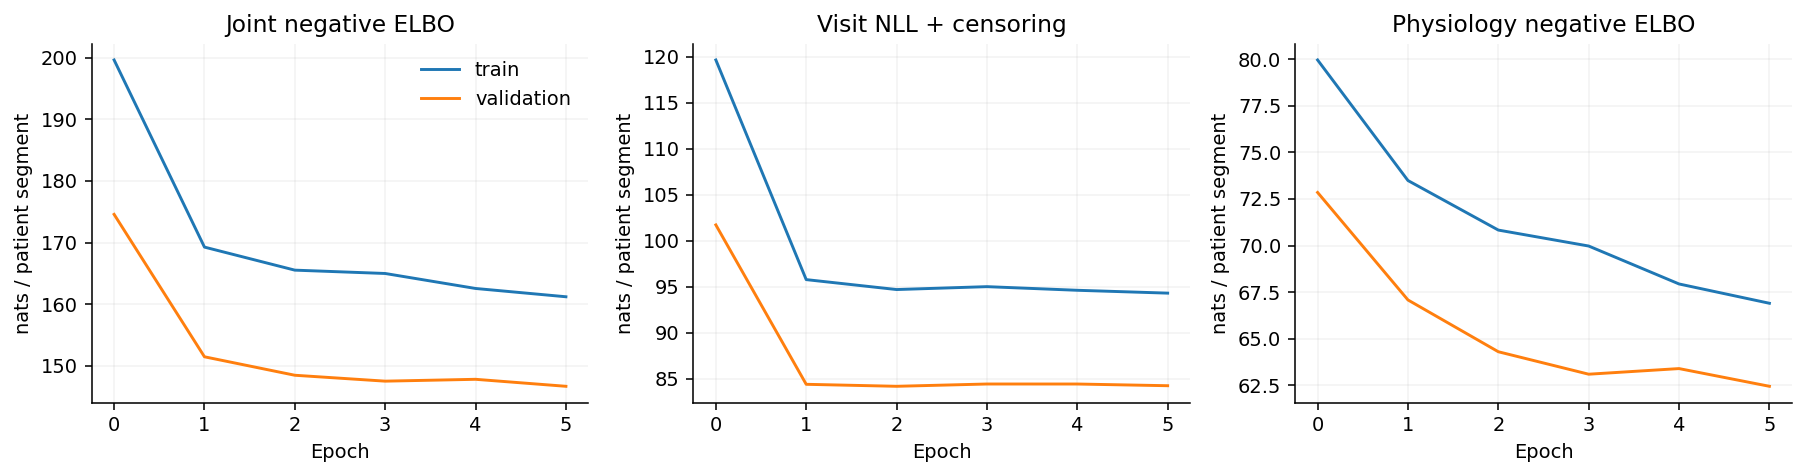

,Visit NLL,Physiology negative ELBO,Joint negative ELBO
0,95.933374,71.647751,167.581125


In [3]:
fig,axes=plt.subplots(1,3,figsize=(13,3.5))
for ax,key,title in zip(axes,["joint_negative_elbo","event_nll","gp_negative_elbo"],
                        ["Joint negative ELBO","Visit NLL + censoring","Physiology negative ELBO"]):
    for split in ("train","validation"):
        ax.plot([h['epoch'] for h in history],[h[split][key] for h in history],label=split)
    ax.set(title=title,xlabel="Epoch",ylabel="nats / patient segment"); ax.grid(alpha=.15)
axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()
test_objective=pd.DataFrame([lifetime.score(patients["test"])]).rename(columns={
    "event_nll":"Visit NLL", "gp_negative_elbo":"Physiology negative ELBO",
    "joint_negative_elbo":"Joint negative ELBO"})
display(test_objective)

### One patient across the lifetime horizon

We now use all observed records of one test patient up to their actual censoring date. Pre-entry time is blank, the observed interval is fitted retrospectively, and the region after censoring is a conditional forecast. The dotted prefix boundary explains where visit fitting begins. We retain all recorded measurement dots, including those in the conditioning prefix.

In [4]:
from lifetime_clinical.visualization.lifetime import (lifetime_predictions,
    plot_lifetime_events, plot_lifetime_physiology)
patient=max(patients["test"],key=lambda p:len(p.block.y))
lifetime_view=lifetime_predictions(lifetime,patient,dataset,pre)
print("Test patient:", patient.patient_id)
print("Entry / prefix origin / censoring ages:",
      [round(lifetime_view[k],2) for k in ("entry","origin","censor")])
print("Pre-entry: no predictions. Future forecast horizon: age 100.")

Test patient: P000189
Entry / prefix origin / censoring ages: [16.0, 18.7, 26.04]
Pre-entry: no predictions. Future forecast horizon: age 100.


### Fitted visit risk, next-IAT density and survival

The first panel shows \(\lambda_k\), the instantaneous marked visit rate. The second shows \(\pi_k f_k\), the density of the next IAT mapped onto arrival age. The third shows \(S\), the probability of no next visit yet. The identity \(f=\lambda S\) connects their shapes. All event types use matching line and marker colours. Observed intervals reset after a visit; after \(C\), only the remaining waiting time to the next visit is forecast. No-event observations at the end of follow-up are included through survival conditioning.

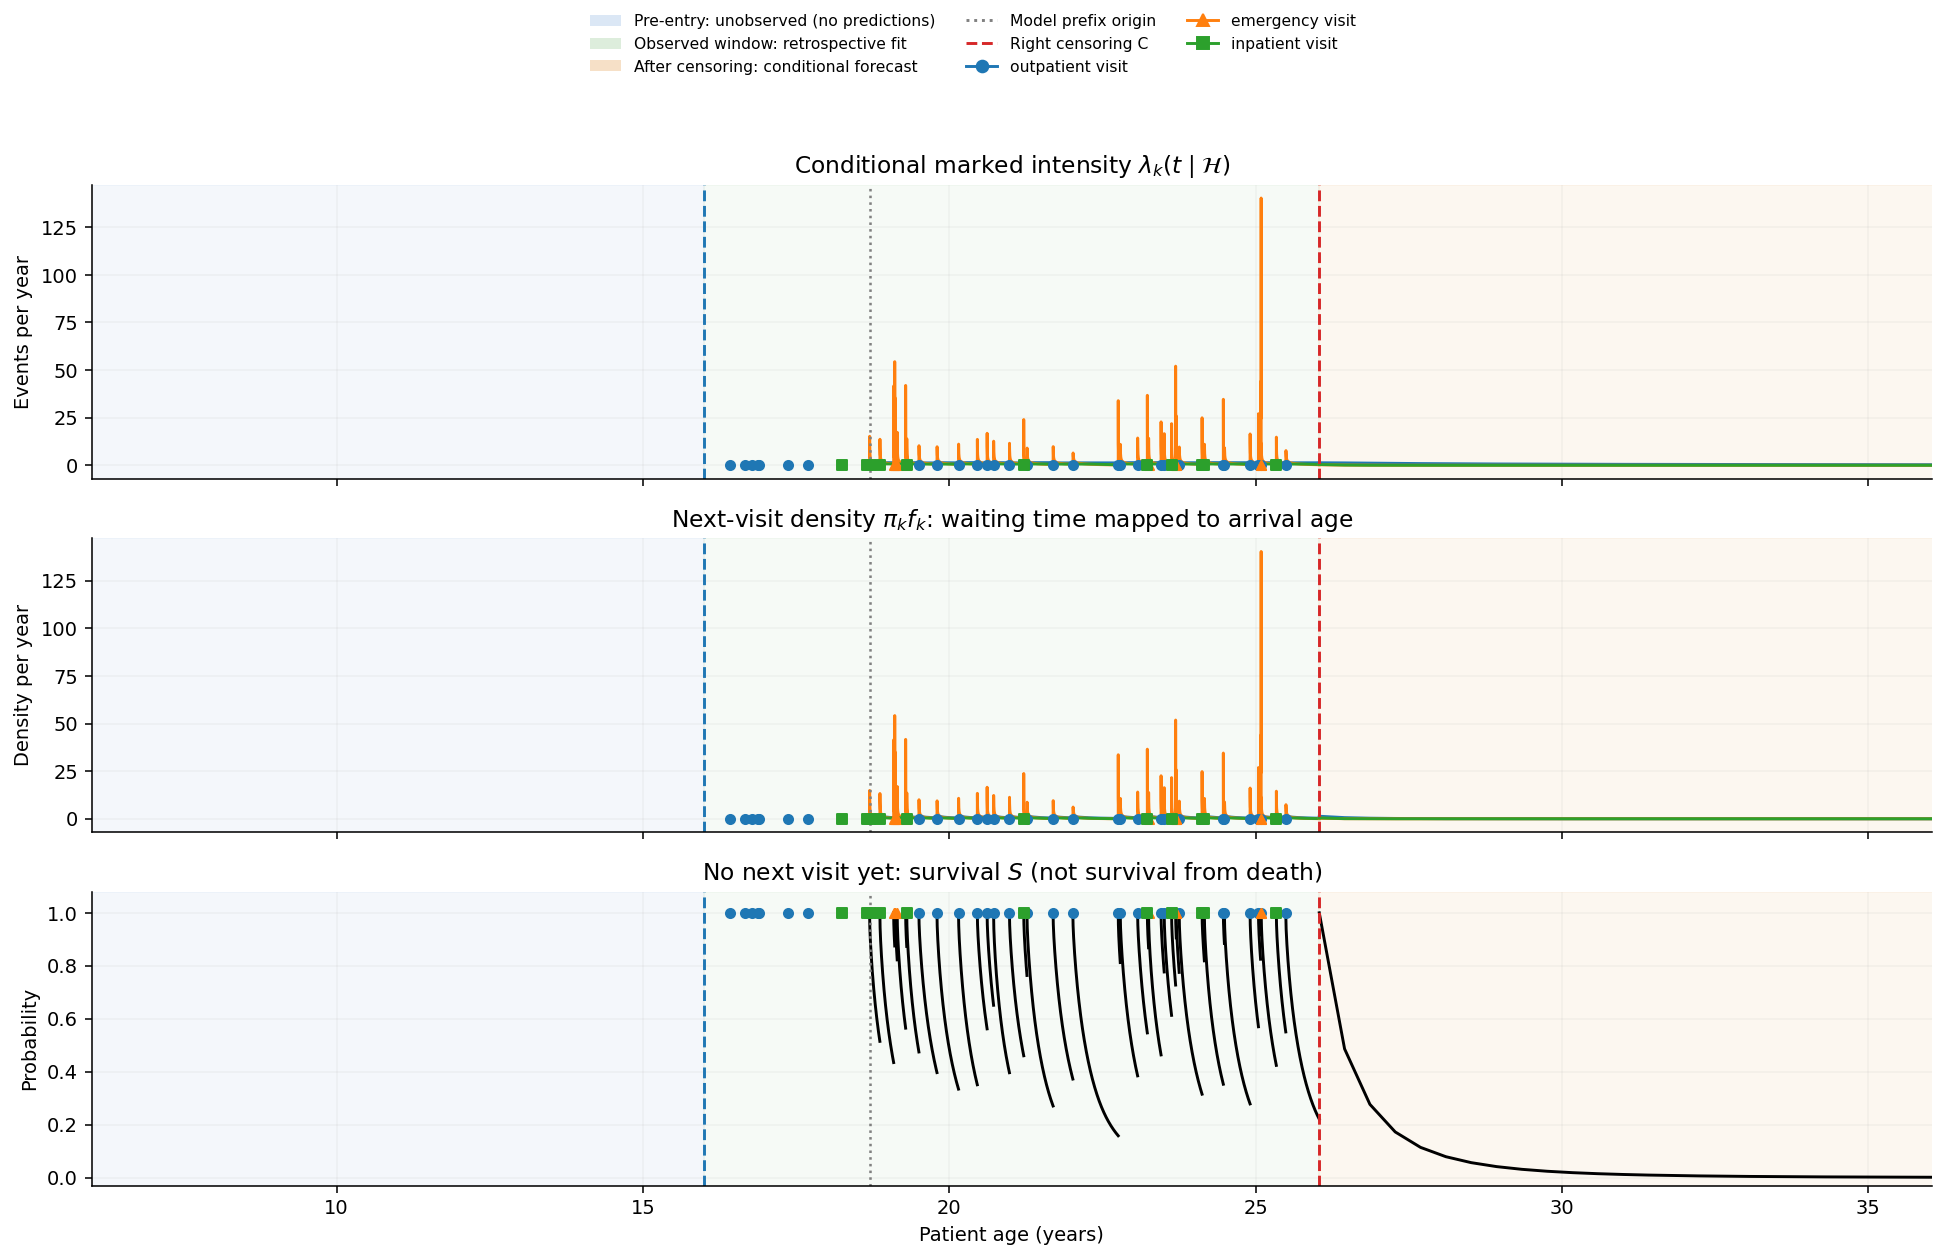

In [5]:
plot_lifetime_events(lifetime_view,patient,dataset,
    age_limits=(max(0,lifetime_view["entry"]-10),min(100,lifetime_view["censor"]+10)))
plt.show()

### Continuous physiology and predicted measured values

We query arbitrary ages throughout the observed and future regions. Thin blue curves are joint draws of latent physiology \(f\); the mean and 10–90% band describe measured values \(y=f+\epsilon\), including residual variability. Red crosses show irregular recorded measurements. The observed-period distribution uses later observed values too and is explicitly retrospective. The prefix contributes to the learned context rather than being scored again as physiological targets. The future region uses only information available by \(C\).

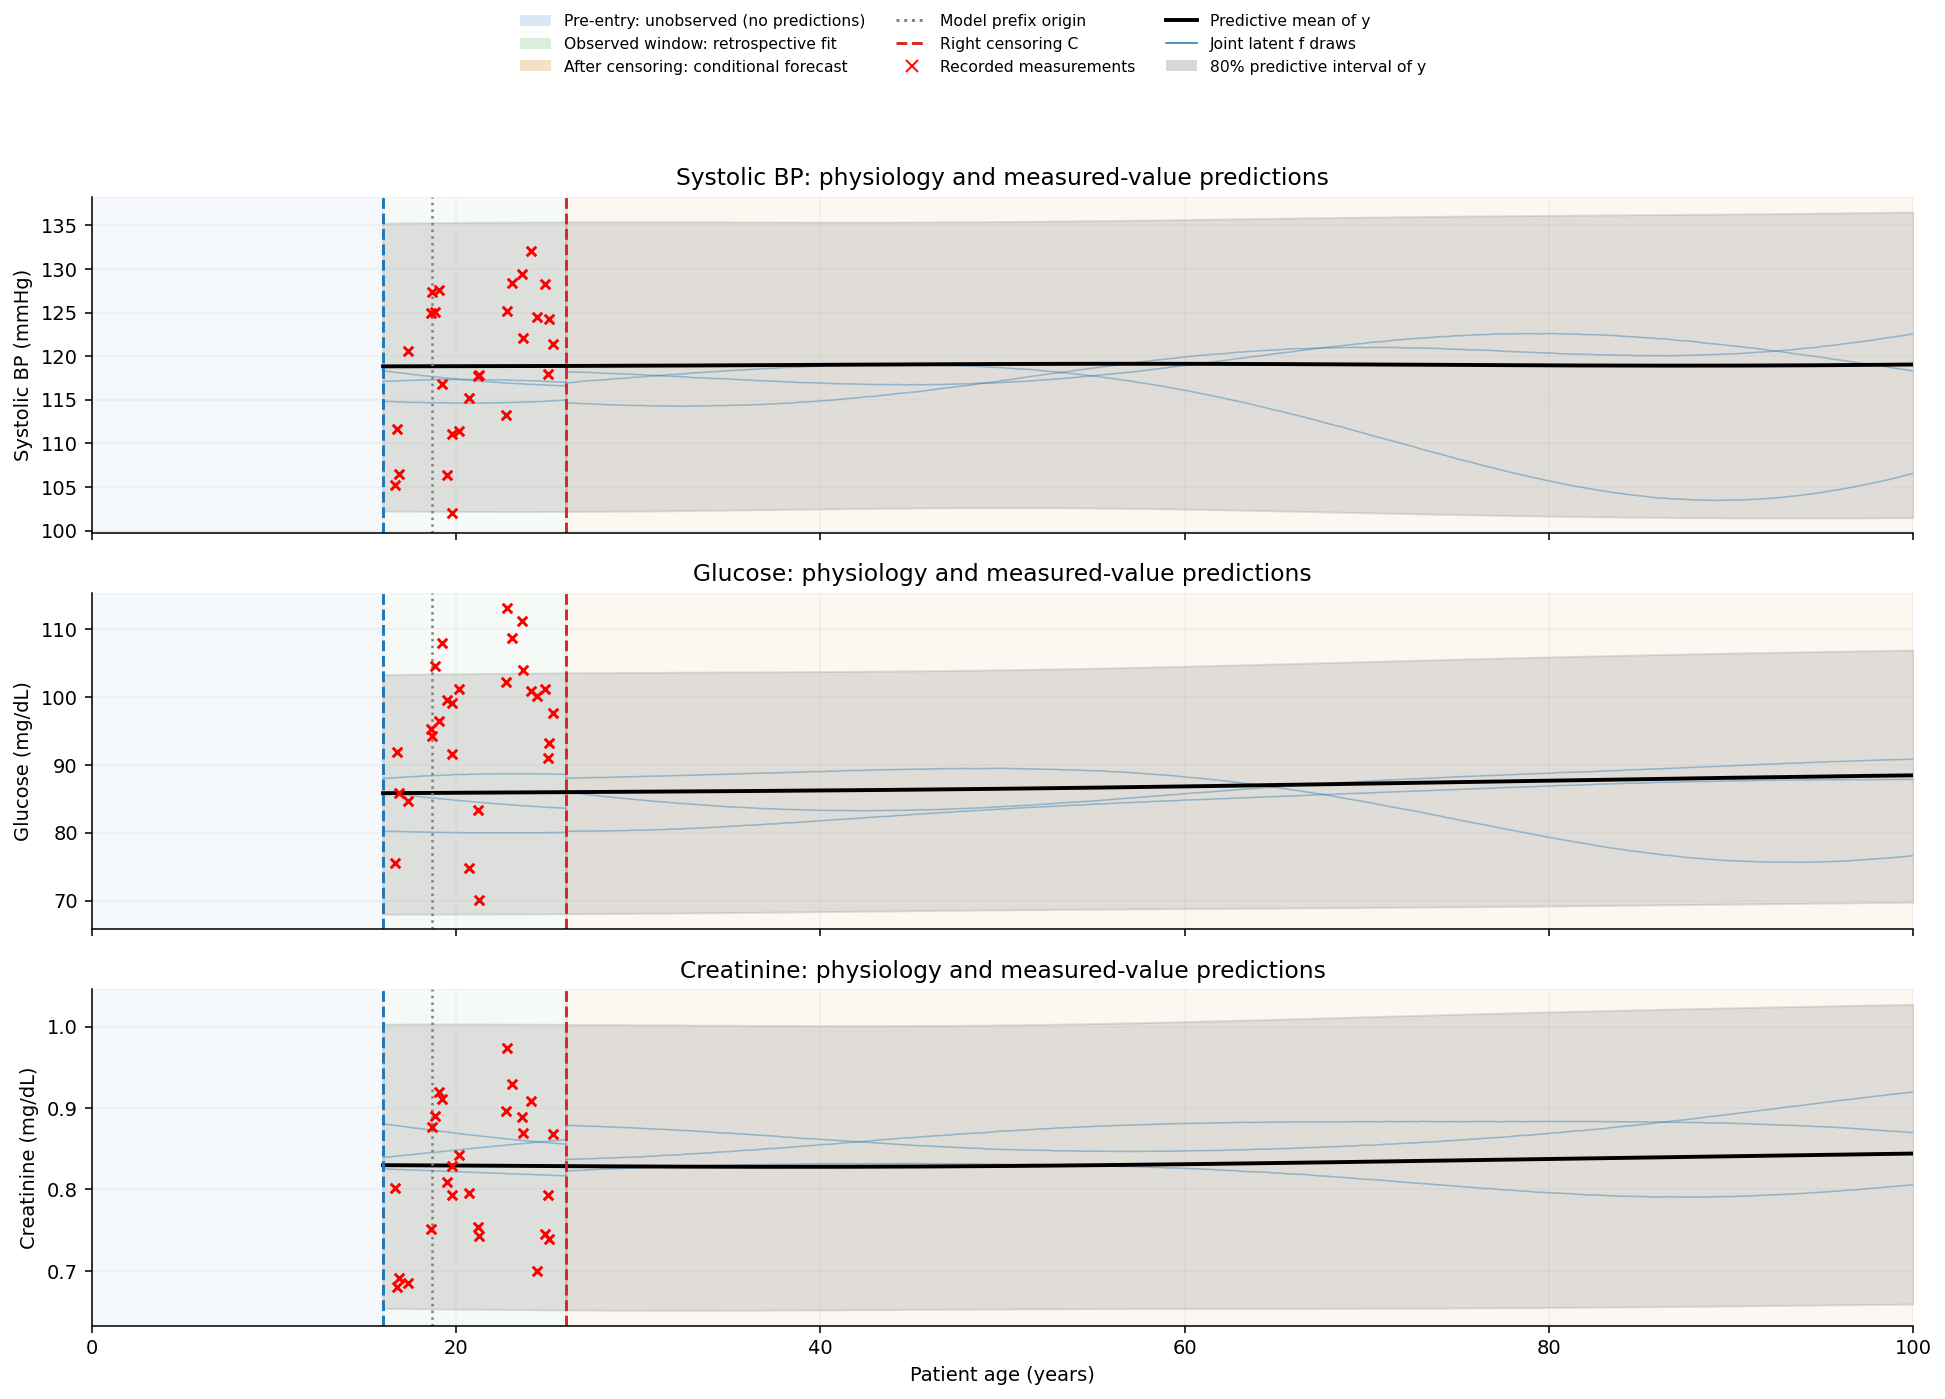

In [6]:
plot_lifetime_physiology(lifetime_view,patient,dataset)
plt.show()

### Predictive physiological feature densities

Each grayscale column is a marginal measured-value density at that age, evaluated by GP-C's numerical quadrature; darker values indicate greater density. Blue means and orange 10/90% quantiles include both latent uncertainty and flow residuals. These are physiological features, not predictions of marital status or employment. A collection of marginal densities alone does not show temporal dependence: the jointly sampled latent trajectories above do. Long-range forecasts may become broad or flat; the model has sparse observations and no biological ageing constraints.

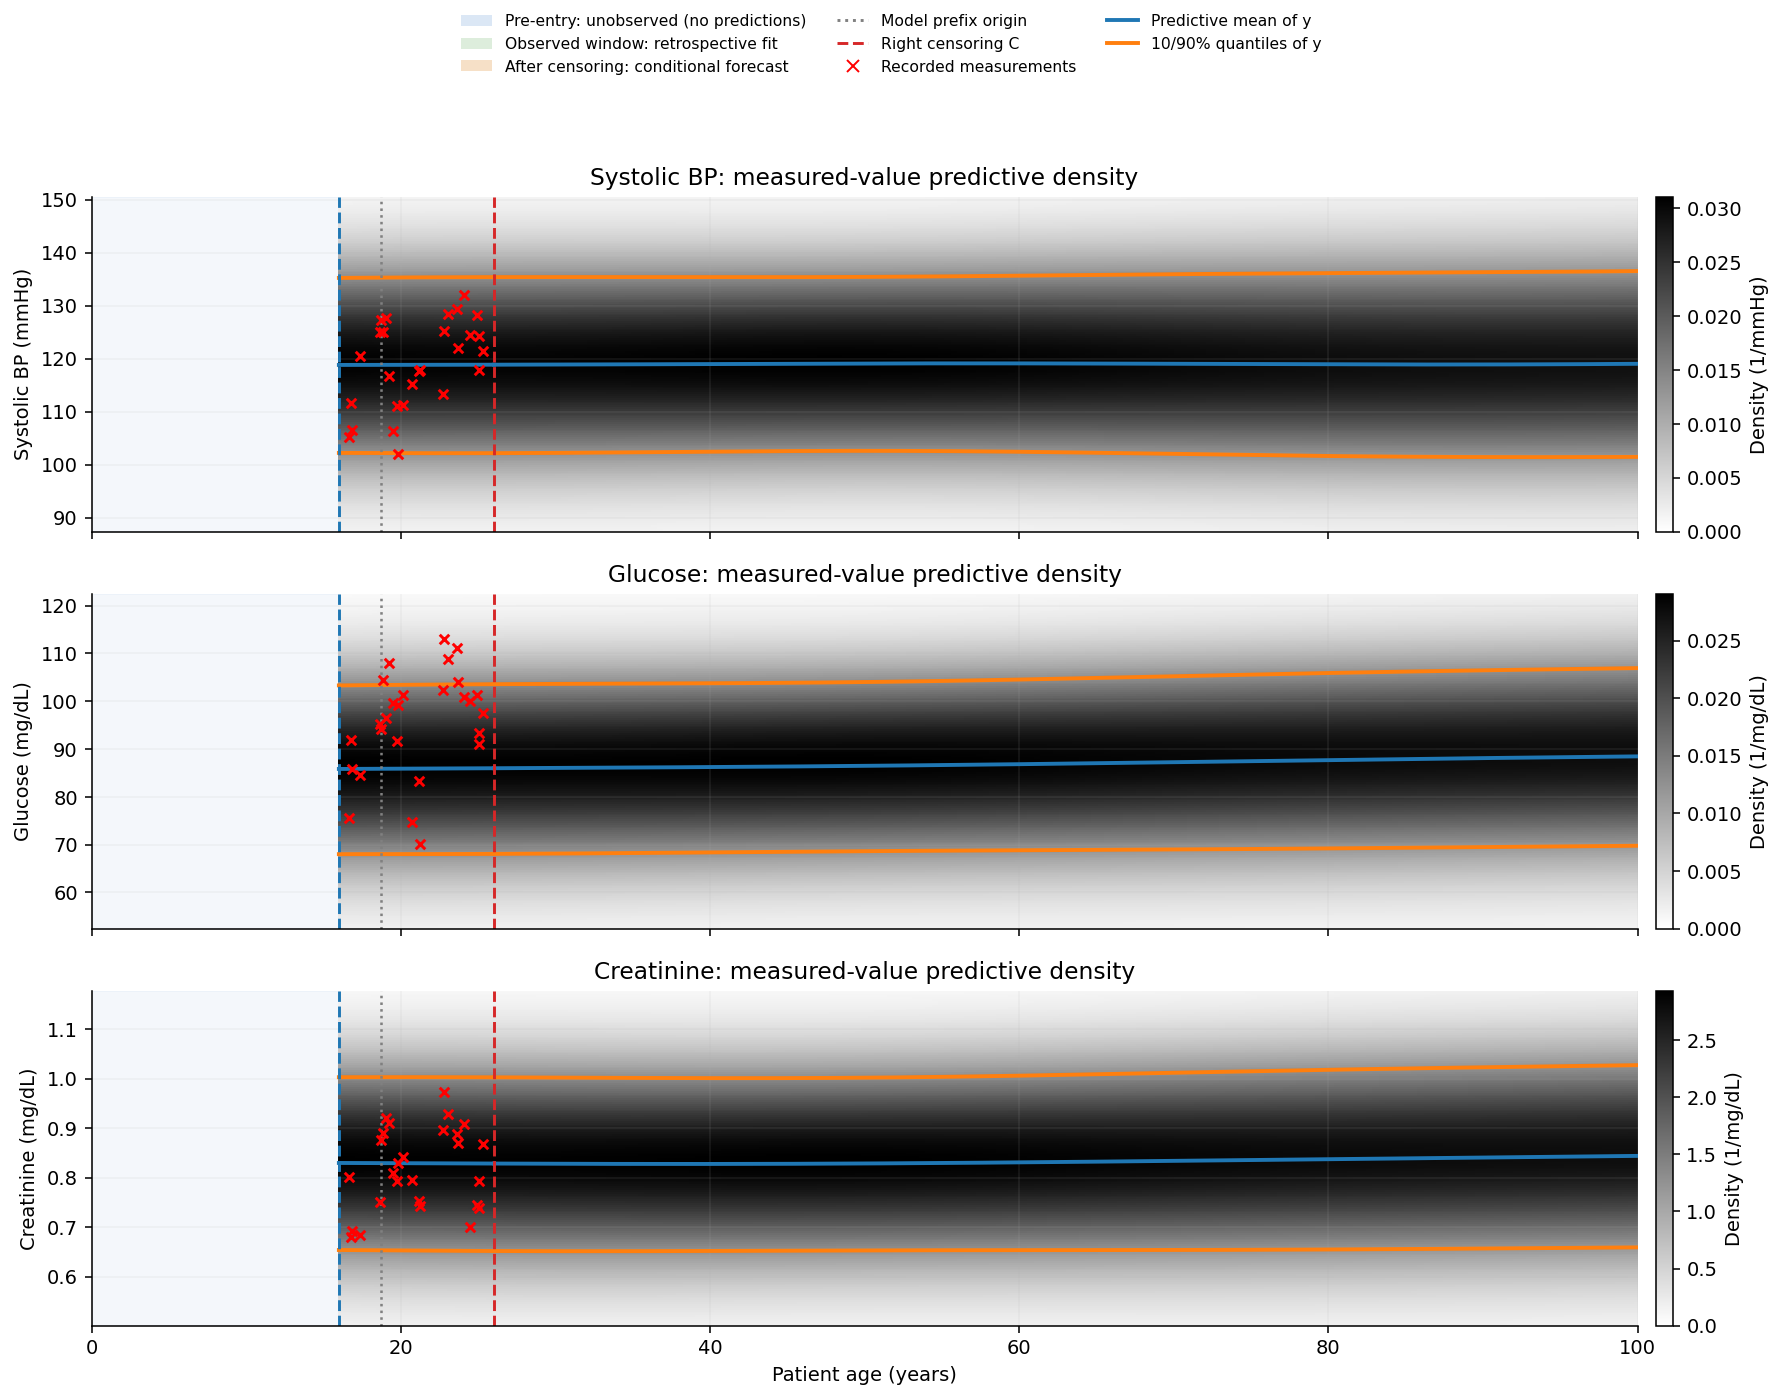

In [7]:
plot_lifetime_physiology(lifetime_view,patient,dataset,density=True)
plt.show()

**How to read the long horizon.** This five-epoch run illustrates fitted and future distributions rather than establishing a detailed individual ageing trajectory. The learned age encoding imposes no periodic cycles; the predicted shape still depends on the available data, kernel and residual model. Far beyond follow-up, evaluate extrapolation separately rather than interpreting a flat or smoothly varying curve as a known biological trajectory.

Next-visit density and survival concern the first future visit. Their decline does not imply that later visits stop occurring; later visits require autoregressive rollout and updates to history. The following prospective check evaluates withheld measurements separately from the retrospective overview.

### A separate prospective check inside follow-up

The lifetime overview uses all available observations. For an honest held-out check, we now reveal only earlier measurement panels and forecast the withheld future. This artificial cutoff is distinct from actual administrative censoring. Held-out values never enter the prediction.

In [8]:
patient=max(patients["test"],key=lambda p:len(p.block.y))
conditioning,heldout=split_forecast_block(patient.block,fraction=.6)
cutoff_age=float(conditioning.ages.max())*100
cutoff_days=(cutoff_age-patient.origin_age)*YEAR_DAYS
print("Test patient:",patient.patient_id,"Cutoff age:",round(cutoff_age,2))
print("Conditioning measurements:",len(conditioning.y),"Held-out measurements:",len(heldout.y))
print("Visits before cutoff:",int((patient.times<=cutoff_days).sum()))

Test patient: P000189 Cutoff age: 22.79
Conditioning measurements: 36 Held-out measurements: 27
Visits before cutoff: 20


### Attribute future uncertainty at the evaluation cutoff

The GP-C decomposition separates latent-function variance from independent residual variance. A large residual share does not automatically mean poor predictions; systematic errors and held-out calibration still need checking.

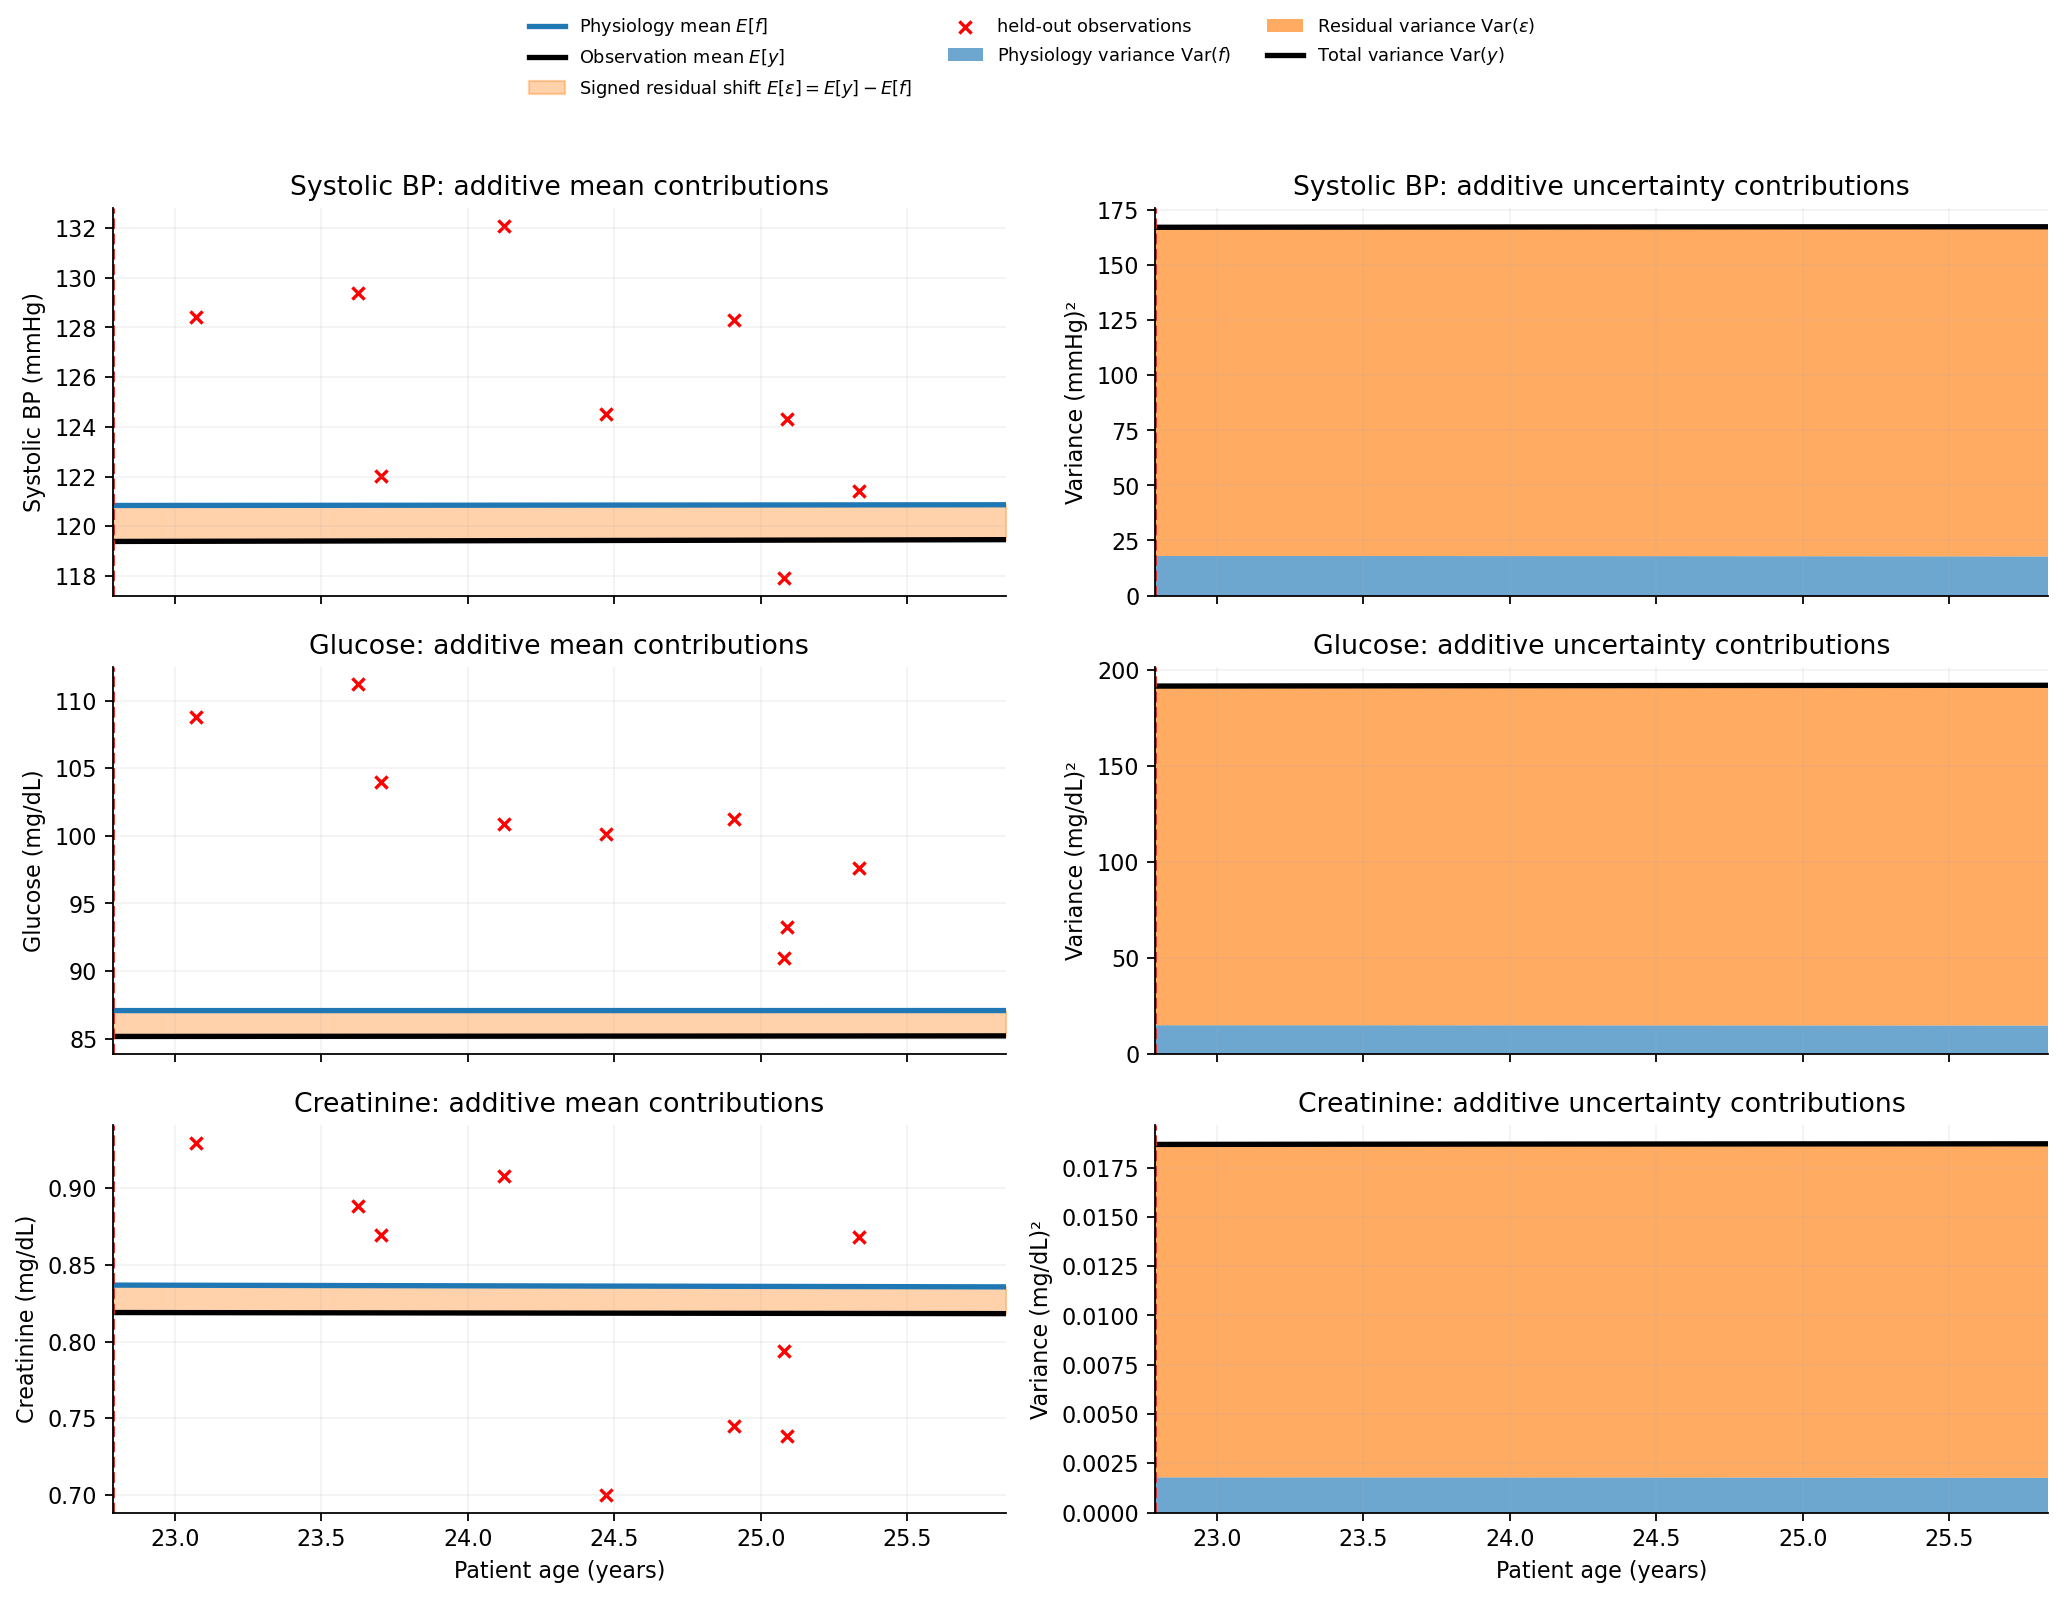

In [9]:
plot_additive_contributions(lifetime.gp,conditioning,heldout,
    np.linspace(cutoff_age,max(heldout.ages)*100+.5,120),cutoff_age)
plt.show()

### Output analysis and held-out checks

We report the change in validation joint negative ELBO and an illustrative held-out physiology check. The conditional physiology score below is a Monte Carlo estimate of a **joint held-out predictive NLL**, not the training ELBO. The coverage calculation uses marginal 10–90% predictive intervals, including residual variation. It covers only one test patient's measurements, so it cannot establish population calibration or a reliable architecture ranking.

In [10]:
heldout_prediction=lifetime.gp.forecast(conditioning,heldout.ages,heldout.variables)
heldout_draws=heldout_prediction.sample(5000,seed=120)
lower,upper=np.quantile(heldout_draws,[.1,.9],axis=0)
coverage=(heldout.raw_y>=lower)&(heldout.raw_y<=upper)
metrics=[]
for d,v in enumerate(VARIABLES):
    mask=heldout.variables==d
    if mask.any():
        metrics.append({"Feature":v,"Held-out measurements":int(mask.sum()),
                        "80% interval coverage":float(coverage[mask].mean()),
                        "Mean absolute error (clinical units)":float(np.mean(np.abs(
                            heldout_prediction.mean[mask]-heldout.raw_y[mask])))})
display(pd.DataFrame(metrics).set_index("Feature"))
initial=history[0]['validation']['joint_negative_elbo']
best=min(h['validation']['joint_negative_elbo'] for h in history)
conditional_nll=-heldout_prediction.log_prob(heldout.raw_y,n_samples=4096,seed=121)
display(Markdown(f"**Observed results.** Validation joint negative ELBO: {initial:.2f} initially → {best:.2f} at the selected checkpoint. "
                 f"The one-patient held-out physiology joint predictive NLL is approximately {conditional_nll:.2f} nats "
                 f"(Monte Carlo), and the marginal 80% intervals cover {coverage.mean():.0%} of {len(coverage)} held-out measurements. "
                 "These fast-mode results test the joint fitting and prediction pipeline. They do not prove calibrated uncertainty, "
                 "an improvement over separately trained branches, or a complete birth-to-death model."))

,Held-out measurements,80% interval coverage,Mean absolute error (clinical units)
Feature,,,
systolic_bp,9,1.000000,6.285120
glucose,9,0.666667,15.688602
creatinine,9,1.000000,0.074047


**Observed results.** Validation joint negative ELBO: 174.58 initially → 146.71 at the selected checkpoint. The one-patient held-out physiology joint predictive NLL is approximately 60.42 nats (Monte Carlo), and the marginal 80% intervals cover 89% of 27 held-out measurements. These fast-mode results test the joint fitting and prediction pipeline. They do not prove calibrated uncertainty, an improvement over separately trained branches, or a complete birth-to-death model.

In [11]:
display(Markdown(f"### Interpretation of this fast-mode run\n\n"
    f"Validation joint negative ELBO changed from {initial:.2f} to {best:.2f} at the selected checkpoint. "
    "This does not establish that sharing outperforms separate models: no controlled comparison was run.\n\n"
    f"The nominal 80% intervals contain {int(coverage.sum())} of {len(coverage)} held-out values "
    f"({coverage.mean():.0%}) for this patient. "
    + ("This example shows undercoverage; " if coverage.mean()<.8 else "This small example is insufficient to establish calibration; ")
    + "correlated measurements from one patient cannot establish population coverage. "
    "Inspect systematic mean errors and evaluate across all test patients.\n\n"
    "Next checks are full-data fitting, an appropriate inducing-point layout, and shared-versus-separate "
    "encoder evaluation on identical targets. The first prototype conditions on measurement times and "
    "does not yet implement a complete birth-to-death model."))

### Interpretation of this fast-mode run

Validation joint negative ELBO changed from 174.58 to 146.71 at the selected checkpoint. This does not establish that sharing outperforms separate models: no controlled comparison was run.

The nominal 80% intervals contain 24 of 27 held-out values (89%) for this patient. This small example is insufficient to establish calibration; correlated measurements from one patient cannot establish population coverage. Inspect systematic mean errors and evaluate across all test patients.

Next checks are full-data fitting, an appropriate inducing-point layout, and shared-versus-separate encoder evaluation on identical targets. The first prototype conditions on measurement times and does not yet implement a complete birth-to-death model.